# Incident reassignment and resolution time
Thanaphoom Babparn · AI Programming Foundations

The Incident Management Process Enriched Event Log records updates to service tickets. This workflow estimates how resolution time varies with reassignment count, giving each incident one vote.

[Public project repository](https://github.com/marttp/ai-programming-foundations-project)

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Data Ingestion

In [2]:
events = pd.read_csv("incident_event_log.csv", na_values=["?"], low_memory=False)
print(events.shape)
display(events.head())

(119998, 36)


,number,incident_state,active,reassignment_count,reopen_count,sys_mod_count,made_sla,caller_id,opened_by,opened_at,...,u_priority_confirmation,notify,problem_id,rfc,vendor,caused_by,closed_code,resolved_by,resolved_at,closed_at
0,INC0000045,New,True,0,0,0,True,Caller 2403,Opened by 8,29/2/2016 01:16,...,False,Do Not Notify,NaN,NaN,NaN,NaN,code 5,Resolved by 149,29/2/2016 11:29,5/3/2016 12:00
1,INC0000045,Resolved,True,0,0,2,True,Caller 2403,Opened by 8,29/2/2016 01:16,...,False,Do Not Notify,NaN,NaN,NaN,NaN,code 5,Resolved by 149,29/2/2016 11:29,5/3/2016 12:00
2,INC0000045,Resolved,True,0,0,3,True,Caller 2403,Opened by 8,29/2/2016 01:16,...,False,Do Not Notify,NaN,NaN,NaN,NaN,code 5,Resolved by 149,29/2/2016 11:29,5/3/2016 12:00
3,INC0000045,Closed,False,0,0,4,True,Caller 2403,Opened by 8,29/2/2016 01:16,...,False,Do Not Notify,NaN,NaN,NaN,NaN,code 5,Resolved by 149,29/2/2016 11:29,5/3/2016 12:00
4,INC0000047,New,True,0,0,0,True,Caller 2403,Opened by 397,29/2/2016 04:40,...,False,Do Not Notify,NaN,NaN,NaN,NaN,code 5,Resolved by 81,1/3/2016 09:52,6/3/2016 10:00


## Data Cleaning
Use the maximum cumulative handoff count. Recover timestamps across snapshots and flag inconsistent endpoints before choosing a duration. Missing resolution times stay unknown.

In [3]:
def parse_ticket_fields(frame):
    """Parse source timestamps as day-first and validate cumulative counts."""
    clean = frame.copy()
    for field in ["opened_at", "resolved_at"]:
        clean[field] = pd.to_datetime(clean[field], format="%d/%m/%Y %H:%M", errors="coerce")
    counts = pd.to_numeric(clean["reassignment_count"], errors="coerce")
    clean["reassignment_count"] = counts.where(counts.ge(0))
    return clean

def collapse_history(frame):
    """Collapse updates to one incident and mask ambiguous or reversed intervals."""
    groups = frame.groupby("number", sort=True)
    tickets = groups.agg(opened=("opened_at", "min"), resolved=("resolved_at", "max"),
                         handoffs=("reassignment_count", "max"), updates=("number", "size"))
    conflicts = groups[["opened_at", "resolved_at"]].nunique().gt(1).any(axis=1)
    elapsed = (tickets.resolved - tickets.opened).dt.total_seconds() / 3600
    tickets["hours"] = elapsed.where(~conflicts & elapsed.ge(0))
    tickets["conflicting_endpoints"] = conflicts
    return tickets

tickets = collapse_history(parse_ticket_fields(events))
print("Tickets, excluded durations, endpoint conflicts:",
      len(tickets), tickets.hours.isna().sum(), tickets.conflicting_endpoints.sum())
display(tickets.head())

Tickets, excluded durations, endpoint conflicts: 20769 1418 0


,opened,resolved,handoffs,updates,hours,conflicting_endpoints
number,,,,,,
INC0000045,2016-02-29 01:16:00,2016-02-29 11:29:00,0,4,10.216667,False
INC0000047,2016-02-29 04:40:00,2016-03-01 09:52:00,1,9,29.200000,False
INC0000057,2016-02-29 06:10:00,2016-03-01 02:55:00,0,7,20.750000,False
INC0000060,2016-02-29 06:38:00,2016-03-02 12:06:00,0,4,53.466667,False
INC0000062,2016-02-29 06:58:00,2016-02-29 15:51:00,1,8,8.883333,False


## Exploratory Analysis
Group eligible incidents by reassignment count and compare their median resolution times.

In [4]:
def summarize_handoffs(frame):
    """Return counts and median resolution hours by cumulative handoff band."""
    complete = frame.dropna(subset=["hours", "handoffs"]).copy()
    complete["band"] = pd.cut(complete.handoffs, [-1, 0, 1, 2, np.inf],
                              labels=["0", "1", "2", "3+"])
    return complete.groupby("band", observed=False).hours.agg(["count", "median"])

summary = summarize_handoffs(tickets)
display(summary)
print("Duration quantiles (hours):", tickets.hours.quantile([.5, .9, .99]).round(2).to_dict())

,count,median
band,,
0,9517,0.783333
1,5361,45.166667
2,1952,111.966667
3+,2521,194.850000


Duration quantiles (hours): {0.5: 24.6, 0.9: 397.37, 0.99: 2952.09}


## Visualizations

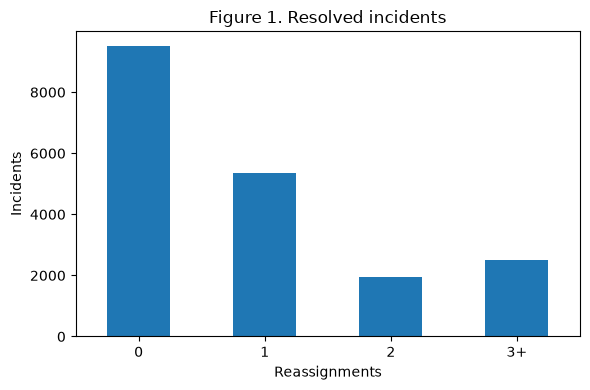

In [5]:
fig, ax = plt.subplots(figsize=(6, 4))
summary["count"].plot.bar(ax=ax, rot=0)
ax.set(title="Figure 1. Resolved incidents", xlabel="Reassignments", ylabel="Incidents")
fig.tight_layout()
plt.show()

**Figure 1.** The 9,517 incidents with zero reassignments make up nearly half of the 19,351 incidents with usable durations.

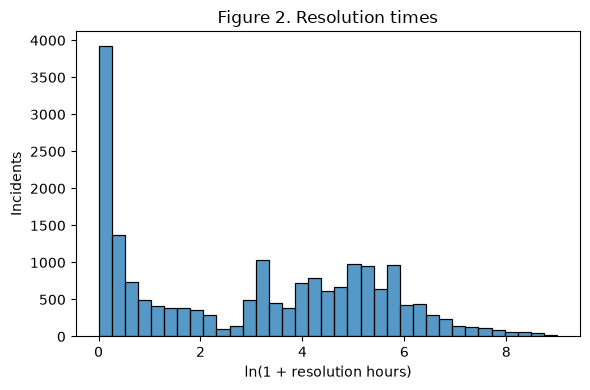

In [6]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.histplot(np.log1p(tickets.hours.dropna()), bins=35, ax=ax)
ax.set(title="Figure 2. Resolution times", xlabel="ln(1 + resolution hours)", ylabel="Incidents")
fig.tight_layout()
plt.show()

**Figure 2.** Durations have a long right tail. The log scale makes short intervals visible alongside cases that took thousands of hours.

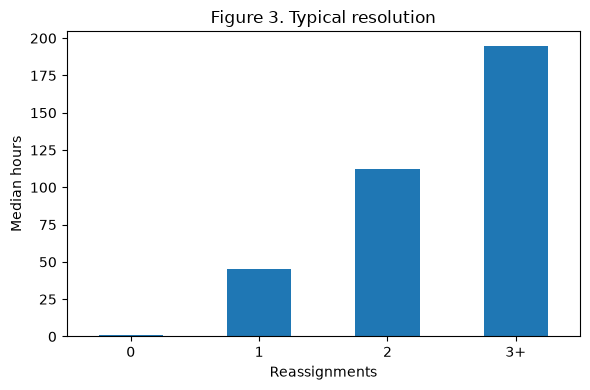

In [7]:
fig, ax = plt.subplots(figsize=(6, 4))
summary["median"].plot.bar(ax=ax, rot=0)
ax.set(title="Figure 3. Typical resolution", xlabel="Reassignments", ylabel="Median hours")
fig.tight_layout()
plt.show()

**Figure 3.** Median resolution time rose from 47 minutes with zero reassignments to 194.85 hours with three or more.

## Findings and Limitations
Of 20,769 incidents, 19,351 had a usable resolution interval. The zero-reassignment group contained 9,517 of them and had a median resolution time of 47 minutes. The median rose to 45.17 hours with one reassignment and 194.85 hours with three or more. One surprise was the long tail: the 99th percentile was about 2,952 hours. Ticket complexity and unresolved cases can affect this comparison, so the pattern cannot establish that handoffs cause delays.